# Fine-tune a small PaddleOCR stack on Vietnamese legal documents

Trains three small models that can run side by side in production: **text detection** (PP-OCRv6 small/tiny), **text recognition** (same family, **new Vietnamese dictionary**) and **layout** (PP-DocLayout-S, legal-document classes).

**Why recognition was bad.** The dictionaries of `latin_PP-OCRv5` and `PP-OCRv6` lack 88-92 of the 134 Vietnamese letters (every letter with two marks: ạ ả ấ ầ ế ề ợ ữ …). A CTC recogniser cannot output a character it has no class for, so more data on the old dictionary cannot fix it. Step 1 prints the gap; step 3 retrains with a new dictionary, starting from the pretrained network.

**How it runs.** Every step is `training/ocr/scripts/run_pipeline.sh` (the cells below call it phase by phase, so the notebook, `colab exec` and a plain Linux GPU box behave the same). It uses two Python 3.12 virtualenvs: Colab's own Python 3.13 has no `paddle2onnx` wheel, and the GPU build of Paddle writes `linear_v2` operators that `paddle2onnx` cannot convert, so export and ONNX run in a second, CPU-build environment.

**Runtime:** Runtime → Change runtime type → GPU (T4 is enough; measured on a T4: ≈ 100 recognition lines/s, about 35 min per epoch of 200k lines). Datasets are built on the local disk; if Google Drive is mounted, `OUT_DIR` below keeps checkpoints there.

In [20]:
#@title 0. Settings
REPO_URL = "https://github.com/xuanvinh1997/vi-legal-ocr-training.git" #@param {type:"string"}
CODE_DIR = "" #@param {type:"string"}
#@markdown `CODE_DIR`: set instead of `REPO_URL` if you copied `training/ocr` to Drive (private repo).
OUT_DIR = "/content/drive/MyDrive/ocr-vi-legal" #@param {type:"string"}
SIZE = "small" #@param ["small", "tiny"]
CORPUS_DOCS = 3000 #@param {type:"integer"}
SYNTH_LINES = 200000 #@param {type:"integer"}
SYNTH_PAGES = 3000 #@param {type:"integer"}
PDF_DIR = "" #@param {type:"string"}
#@markdown `PDF_DIR`: folder of born-digital legal PDFs. Optional, but real pages are the most valuable data (`PDF_REPEAT` = how many times they are listed in the training set).
PDF_REPEAT = 3 #@param {type:"integer"}
REC_EPOCHS = 6 #@param {type:"integer"}
REC_BATCH = 32 #@param {type:"integer"}
DET_EPOCHS = 30 #@param {type:"integer"}
DET_BATCH = 8 #@param {type:"integer"}
LAYOUT_EPOCHS = 40 #@param {type:"integer"}
LAYOUT_BATCH = 8 #@param {type:"integer"}
RESUME = True #@param {type:"boolean"}

In [35]:
import json, os, pathlib, random, shutil, subprocess, sys

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("not on Colab")
if not pathlib.Path("/content/drive").exists():
    OUT_DIR = "/content/out"
    print("Drive not mounted: checkpoints stay on this VM in", OUT_DIR)

WORK, DATA = pathlib.Path("/content"), pathlib.Path("/content/data")

# Đảm bảo dọn dẹp biến CODE_DIR nếu nó trỏ sai cấu trúc repo cũ
if not CODE_DIR or CODE_DIR.endswith("training/ocr"):
    CODE_DIR = "/content/private-ai"

if not (WORK / "private-ai").exists():
    !git clone -q --depth 1 {REPO_URL} /content/private-ai

SCRIPT = f"{CODE_DIR}/scripts/run_pipeline.sh"
ENV = " ".join(f"{k}={v}" for k, v in dict(
    CODE=CODE_DIR, OUT=OUT_DIR, SIZE=SIZE, CORPUS_DOCS=CORPUS_DOCS, SYNTH_LINES=SYNTH_LINES, SYNTH_PAGES=SYNTH_PAGES, PDF_DIR=PDF_DIR or "",
    PDF_REPEAT=PDF_REPEAT, REC_EPOCHS=REC_EPOCHS, REC_BATCH=REC_BATCH, DET_EPOCHS=DET_EPOCHS, DET_BATCH=DET_BATCH,
    LAYOUT_EPOCHS=LAYOUT_EPOCHS, LAYOUT_BATCH=LAYOUT_BATCH, RESUME=int(RESUME)).items())
GPU_PY, CPU_PY = "/content/venv/bin/python", "/content/venv_cpu/bin/python"
print(ENV)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CODE=/content/private-ai OUT=/content/drive/MyDrive/ocr-vi-legal SIZE=small CORPUS_DOCS=3000 SYNTH_LINES=200000 SYNTH_PAGES=3000 PDF_DIR= PDF_REPEAT=3 REC_EPOCHS=6 REC_BATCH=32 DET_EPOCHS=30 DET_BATCH=8 LAYOUT_EPOCHS=40 LAYOUT_BATCH=8 RESUME=1


In [36]:
import os

def list_files(startpath):
    for root, dirs, files in os.walk(startpath):
        # Exclude common large directories to avoid flooding the output
        dirs[:] = [d for d in dirs if d not in ['.git', 'venv', 'venv_cpu', 'drive', 'data', 'sample_data']]
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        for f in files[:15]: # Show up to 15 files per directory
            print(f'{subindent}{f}')

print("--- Cấu trúc thư mục tại /content (đã lọc bớt các thư mục lớn) ---")
list_files('/content')

--- Cấu trúc thư mục tại /content (đã lọc bớt các thư mục lớn) ---
content/
    status
    data.zip
    .config/
        .last_survey_prompt.yaml
        .last_update_check.json
        active_config
        hidden_gcloud_config_universe_descriptor_data_cache_configs.db
        config_sentinel
        .last_opt_in_prompt.yaml
        default_configs.db
        gce
        configurations/
            config_default
        logs/
            2026.10.21/
                13.27.51.774504.log
                13.28.05.116687.log
                13.27.28.750982.log
                13.28.04.564766.log
                13.27.57.480371.log
                13.27.58.650478.log
    pretrained/
        rec.pdparams
    __MACOSX/
        ._data
    private-ai/
        requirements.txt
        pyproject.toml
        README.md
        .gitignore
        scripts/
            run_pipeline.sh
        tests/
            test_synth_pages.py
            test_pdf_labels.py
            test_geometry.py
         

## 1. Datasets

Built under `/content/data` in the layout PaddleOCR reads (`rec/`, `det/`, `layout/`). Shards: `synth_lines` (real legal text from the CC-BY-4.0 corpus [th1nhng0/vietnamese-legal-documents](https://huggingface.co/datasets/th1nhng0/vietnamese-legal-documents) in Times-style fonts with scan degradations), `synth_pages` (full A4 pages: motto, issuer, title, justified body, tables, recipients, signature, seal; labels for det + layout + rec) and, if `PDF_DIR` is set, `pdf` (your PDFs; scans and broken encodings are skipped and counted).

The first lines of the output show which Vietnamese letters the stock dictionary cannot produce.

In [ ]:
!rm -rf data/

In [3]:
!cp -r drive/MyDrive/Workspaces/Shared/Datasets/OCR/data.zip .

In [ ]:
!unzip data.zip

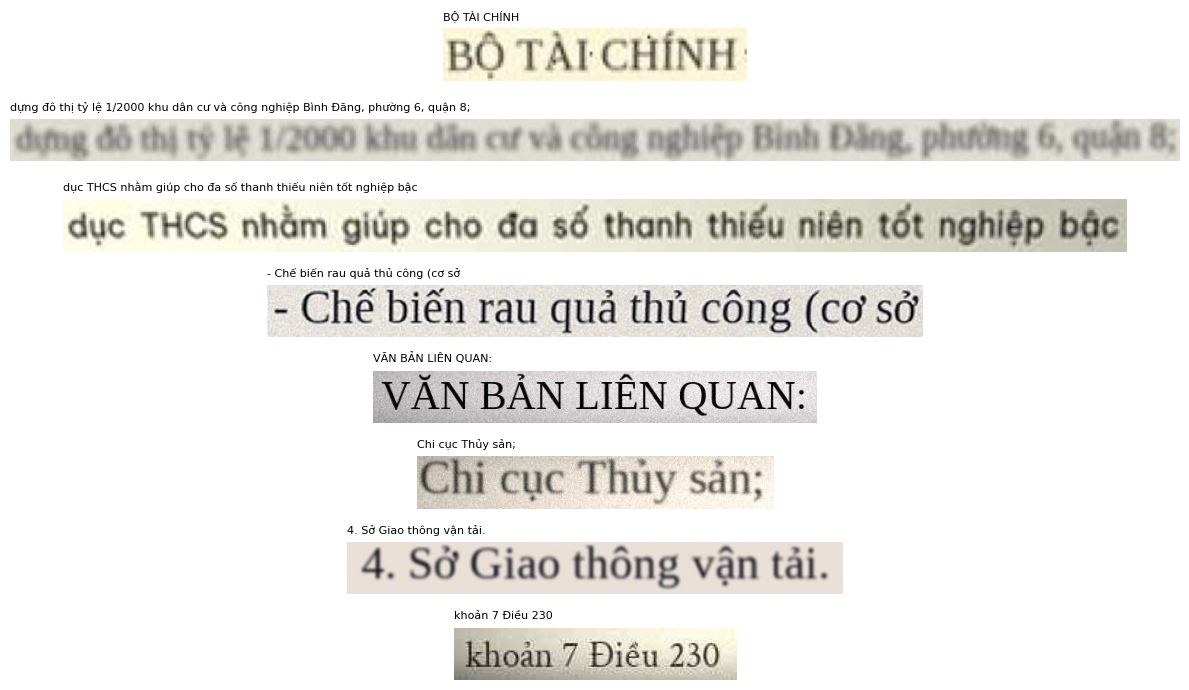

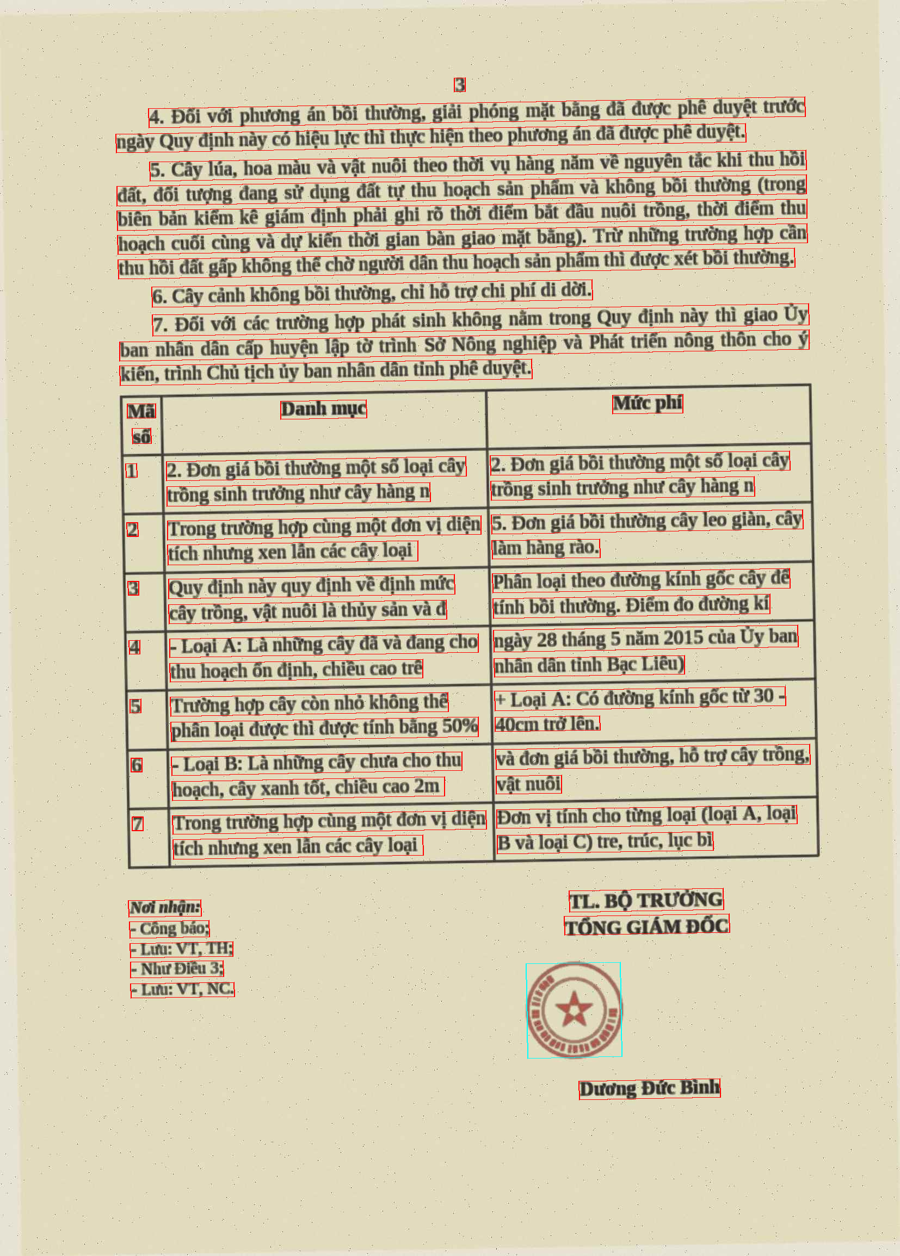

In [5]:
# Look at the data before spending GPU hours on it. Red boxes = text lines, cyan = ignored (seal, signature).
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

rec = [l.split("\t") for l in (DATA / "rec/train_list.txt").read_text(encoding="utf-8").splitlines()]
fig, axes = plt.subplots(8, 1, figsize=(12, 7))
for ax, (rel, text) in zip(axes, random.sample(rec, 8)):
    ax.imshow(Image.open(DATA / "rec" / rel)); ax.set_title(text[:110], fontsize=8, loc="left"); ax.axis("off")
plt.tight_layout(); plt.show()

det = [l.split("\t", 1) for l in (DATA / "det/train_list.txt").read_text(encoding="utf-8").splitlines()]
rel, payload = random.choice(det)
page = Image.open(DATA / "det" / rel).convert("RGB"); draw = ImageDraw.Draw(page)
for item in json.loads(payload):
    draw.polygon([tuple(p) for p in item["points"]], outline="cyan" if item["transcription"] == "###" else "red", width=2)
page.thumbnail((900, 1300)); display(page)

In [ ]:
#@title Optional: keep the dataset on Drive (a new session restores it instead of rebuilding)
BACKUP_DATA = False #@param {type:"boolean"}
if BACKUP_DATA:
    !tar -C /content -cf {OUT_DIR}/data.tar data
    !ls -lh {OUT_DIR}/data.tar
elif pathlib.Path(OUT_DIR, "data.tar").exists() and not DATA.exists():
    !tar -C /content -xf {OUT_DIR}/data.tar

## 2. Install PaddlePaddle (GPU) and baseline

Done after the data on purpose (the Paddle stack pins `numpy`, which can break `datasets`). The baseline is the stock recogniser on the same held-out lines: `tone-error-share` is the part of the character error that disappears when tone marks are ignored, i.e. what a missing dictionary entry causes.

In [44]:
!{ENV} PHASES="setup install" bash {SCRIPT}


=== [10:14:21] setup
Note: switching to 'b03f46425e8ff4442b268ce449e3eef758146cd4'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false


=== [10:14:30] install paddle (GPU build)
PaddlePaddle works well on 1 GPU.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.

=== [10:14:39] DONE (setup install)


In [43]:
with open('/content/private-ai/scripts/run_pipeline.sh', 'r', encoding='utf-8') as f:
    lines = f.readlines()
    # Print lines around step install
    for idx, line in enumerate(lines):
        if 'install' in line or 'PaddleOCR' in line:
            print(f"{idx+1}: {line}", end="")

4: #   PHASES="setup data install rec det layout export" bash run_pipeline.sh      (all knobs below are environment variables)
10: : "${PHASES:=setup data install rec det layout export}"
16: PO=$WORK/PaddleOCR; PX=$WORK/PaddleX; W=$WORK/pretrained; CFG=$OUT/configs; FONTS=$WORK/fonts
33:   [ -d "$PO" ] || git clone -q --depth 1 --branch v3.7.0 https://github.com/PaddlePaddle/PaddleOCR.git "$PO" || die clone
34:   pip install -q -e "$CODE" || die pip-code
49: if has install; then
50:   step "install paddle (GPU build)"
52:   pip install -q paddlepaddle-gpu==3.3.1 --index-url "https://www.paddlepaddle.org.cn/packages/stable/$TAG/" --extra-index-url https://pypi.org/simple --index-strategy unsafe-best-match || die paddle
53:   pip install -q "paddleocr==3.7.0" "paddlex[ocr-core]==3.7.2" pycocotools "setuptools<81" -r "$PO/requirements.txt" || die pip-paddleocr
74:   # `paddlex --install` prompts when the plugin already exists, so only run it once
75:   (cd "$PX" && pip install -q -e . && 

In [45]:
EVAL_LIST = "pdf/val.txt" if PDF_DIR and (DATA / "rec/pdf/val.txt").exists() else "val_list.txt"
print("evaluating on", EVAL_LIST)
!{GPU_PY} -m ocr_train --data {DATA} eval-rec --list {EVAL_LIST} --model-name PP-OCRv6_{SIZE}_rec --limit 1500

evaluating on val_list.txt
/content/venv/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-OCRv6_small_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_small_rec`.



Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/private-ai/ocr_train/__main__.py", line 3, in <module>
    raise SystemExit(main())
                     ^^^^^^
  File "/content/private-ai/ocr_train/cli.py", line 209, in main
    args

## 3. Recognition

`surgery` builds the new classifier head (characters the old dictionary had keep their pretrained column; new letters start from their tone-stripped base, ế ← ê). The config is derived from the upstream recipe with: `max_text_length` from the data (the default 25 **silently drops** longer labels), a wide input with width-aware batching (`ds_width`, lines of similar width share a batch, so short lines are not padded to 1600 px), and no `RecAug` (the data is already degraded; it halves throughput on 2 CPU cores).

In [ ]:
!{ENV} PHASES="rec" bash {SCRIPT}


=== [12:53:00] rec: train
{'copied': 207, 'from_base': 88, 'random': 1} -> /content/pretrained/rec_vi.pdparams
/content/drive/MyDrive/ocr-vi-legal/configs/rec.yml

=== [15:36:09] DONE (rec)


### 3.1. Tiếp tục Train Recognition (Resume Training)
Chúng ta sẽ ghi đè cấu hình `REC_EPOCHS` thành 12 (hoặc cao hơn tùy bạn) và bật `RESUME=1` để huấn luyện nối tiếp từ checkpoint epoch 6 có sẵn ở Google Drive.

In [46]:
# Tăng số Epochs muốn đạt tới và đặt RESUME = True
NEW_REC_EPOCHS = 32  # Tổng số epochs sau khi train xong
RESUME = True

# Đảm bảo dùng đúng CODE_DIR đã được định nghĩa chuẩn ở trên
if not 'CODE_DIR' in globals() or CODE_DIR.endswith("training/ocr"):
    CODE_DIR = "/content/private-ai"

# Cập nhật lại chuỗi môi trường ENV
ENV_RESUME = " ".join(f"{k}={v}" for k, v in dict(
    CODE=CODE_DIR, OUT=OUT_DIR, SIZE=SIZE, CORPUS_DOCS=CORPUS_DOCS, SYNTH_LINES=SYNTH_LINES, SYNTH_PAGES=SYNTH_PAGES, PDF_DIR=PDF_DIR or "",
    PDF_REPEAT=PDF_REPEAT, REC_EPOCHS=NEW_REC_EPOCHS, REC_BATCH=REC_BATCH, DET_EPOCHS=DET_EPOCHS, DET_BATCH=DET_BATCH,
    LAYOUT_EPOCHS=LAYOUT_EPOCHS, LAYOUT_BATCH=LAYOUT_BATCH, RESUME=int(RESUME)).items())

print("Môi trường chạy tiếp tục:", ENV_RESUME)

Môi trường chạy tiếp tục: CODE=/content/private-ai OUT=/content/drive/MyDrive/ocr-vi-legal SIZE=small CORPUS_DOCS=3000 SYNTH_LINES=200000 SYNTH_PAGES=3000 PDF_DIR= PDF_REPEAT=3 REC_EPOCHS=32 REC_BATCH=32 DET_EPOCHS=30 DET_BATCH=8 LAYOUT_EPOCHS=40 LAYOUT_BATCH=8 RESUME=1


In [ ]:
# Chạy lệnh train tiếp tục cho pha 'rec'
!{ENV_RESUME} PHASES="rec" bash {SCRIPT}


=== [10:15:10] rec: train
{'copied': 207, 'from_base': 88, 'random': 1} -> /content/pretrained/rec_vi.pdparams
/content/drive/MyDrive/ocr-vi-legal/configs/rec.yml


## 4. Detection

Upstream det recipe with pretrained weights; rotation augmentation ±10° instead of ±45° (documents are near-horizontal), and `###` regions (seal, signature) are ignored rather than learnt as text. Batch 8: batch 16 runs out of memory on a T4.

In [ ]:
!{ENV} PHASES="det" bash {SCRIPT}


=== [15:57:56] det: train
/content/drive/MyDrive/ocr-vi-legal/configs/det.yml
^C


## 5. Layout

Legal classes (`national_header`, `issuer`, `doc_number_date`, `doc_title`, `para_title`, `text`, `table`, `signature`, `recipients`, `seal`, `page_number`) fine-tuned from PP-DocLayout-S through PaddleX. Synthetic pages teach classes and geometry; append a few hundred hand-labelled real pages (COCO) to `data/layout` for real scans.

In [ ]:
!{ENV} PHASES="layout" bash {SCRIPT}

## 6. Export

Paddle inference models plus ONNX (dynamic batch and width) in `OUT_DIR/export/{rec,det,layout}`. Recognition `inference.yml` is patched so the minimum padded width returns to 320 (the wide training shape would otherwise pad every line at inference). Detection ONNX needs its float64 interpolation attribute rewritten first (done automatically). Recognition and detection ONNX are compared with Paddle numerically; layout is checked for conversion only.

In [ ]:
!{ENV} PHASES="export" bash {SCRIPT}

## 7. Evaluate and try it

In [ ]:
!{CPU_PY} -m ocr_train --data {DATA} eval-rec --list {EVAL_LIST} --model-name PP-OCRv6_{SIZE}_rec --model-dir {OUT_DIR}/export/rec --limit 1500

In [ ]:
# The three exported models together through the public PaddleOCR API.
pathlib.Path("/content/demo.py").write_text(f"""
import json, random, sys
from paddleocr import PaddleOCR, LayoutDetection
E, SIZE, DATA = "{OUT_DIR}/export", "{SIZE}", "{DATA}"
rel = random.choice([l.split("\\t")[0] for l in open(DATA + "/det/val_list.txt", encoding="utf-8").read().split("\\n") if l])
page = DATA + "/det/" + rel
ocr = PaddleOCR(text_detection_model_name=f"PP-OCRv6_{{SIZE}}_det", text_detection_model_dir=E + "/det",
                text_recognition_model_name=f"PP-OCRv6_{{SIZE}}_rec", text_recognition_model_dir=E + "/rec",
                use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False)
res = ocr.predict(page)[0]
for text, score in list(zip(res["rec_texts"], res["rec_scores"]))[:15]:
    print(f"{{float(score):.2f}}  {{text}}")
layout = LayoutDetection(model_name="PP-DocLayout-S", model_dir=E + "/layout")
print([(b["label"], round(b["score"], 2)) for b in layout.predict(page, batch_size=1)[0]["boxes"]][:12])
""")
!{CPU_PY} /content/demo.py 2>&1 | grep -vE "Warning|warn|ccache|INFO|Creating model|PIR pass"

## Using the result

* Paddle: `PaddleOCR(text_detection_model_dir=..., text_recognition_model_dir=...)` as above.
* ONNX Runtime: `export/*/model.onnx`. For parallel serving give each model its own session and a thread pool and keep `intra_op_num_threads` at 1-2 per session so they do not fight for cores.
* To resume after a disconnect: set `RESUME` and run the phase cells again (rec and det continue from `latest`).